### load modules and set paths

In [ ]:
import scanpy as sc
import pandas as pd
import scvi

In [ ]:
# %load_ext lab_black

In [ ]:
atlas_path = "../../../../../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/HLCA_extended/clean_objects_to_share/d10_1101_2022_03_10_483747/homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747.h5ad"

### load and prepare data

In [ ]:
adata_full = sc.read_h5ad(atlas_path, backed="r")

In [ ]:
query_dataset = "Tata_unpubl"

In [ ]:
genes_for_integration = pd.read_csv(
    "../../../../mapping_data_to_the_HLCA/supporting_files/HLCA_scarches_gene_order.csv",
    index_col=0,
)

In [ ]:
genes_for_integration.head(5)

subset to hvgs and to query dataset of interest

In [ ]:
adata_full.var.index.isin(genes_for_integration.index).sum()

In [ ]:
adata_full.layers['counts'] = adata_full.raw.X

In [ ]:
adata = adata_full[
    (adata_full.obs.core_or_extension == "core")
    | (adata_full.obs.dataset == query_dataset),
    adata_full.var.index.isin(genes_for_integration.index),
]

In [ ]:
adata = adata.to_memory()

set scanvi label to unlabeled for query dataset:

In [ ]:
adata.obs.loc[adata.obs.dataset == query_dataset, "scanvi_label"] = "unlabeled"

check that counts layer has integers:

In [ ]:
adata.shape

In [ ]:
adata.layers['counts'].shape

In [ ]:
adata.layers['counts'][:10,:10].toarray()

In [ ]:
adata.layers['counts'][-10:,-10:].toarray()

### Integrate:

In [ ]:
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="dataset")

define parameters (recommended for scArches):

In [ ]:
# arches_params = dict(
#     use_layer_norm="both",
#     use_batch_norm="none",
#     encode_covariates=True,
#     dropout_rate=0.2,
#     n_layers=2,
# )

In [ ]:
scvi_model = scvi.model.SCVI(adata, n_latent=30, gene_likelihood='nb')

In [20]:
scvi_model.train(max_epochs=500)

Epoch 500/500: 100%|██████████| 500/500 [5:26:15<00:00, 36.14s/it, loss=582, v_num=1]  

`Trainer.fit` stopped: `max_epochs=500` reached.


Epoch 500/500: 100%|██████████| 500/500 [5:26:15<00:00, 39.15s/it, loss=582, v_num=1]


In [21]:
scanvi_model = scvi.model.SCANVI.from_scvi_model(scvi_model,labels_key="scanvi_label",unlabeled_category="unlabeled")

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scvi/data/_utils.py:175: UserWarning: Category 18 in adata.obs['_scvi_labels'] has fewer than 3 cells. Models may not train properly.
  warnings.warn(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scvi/data/_utils.py:175: UserWarning: Category 18 in adata.obs['_scvi_labels'] has fewer than 3 cells. Models may not train properly.
  warnings.warn(


In [22]:
scanvi_model.train(200)

INFO     Training for 200 epochs.                                                                                  


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_ ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_ ...
  rank_zero_warn(
LOCAL_RANK: 0 - CU

Epoch 200/200: 100%|██████████| 200/200 [4:58:20<00:00, 93.08s/it, loss=703, v_num=1]  

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [4:58:20<00:00, 89.50s/it, loss=703, v_num=1]


In [23]:
scanvi_model.save(f"./scanvi_models/{query_dataset}", overwrite=True)

In [24]:
scanvi_model

ScanVI Model with the following params: 
unlabeled_category: unlabeled, n_hidden: 128, n_latent: 30, n_layers: 1, dropout_rate: 0.1, dispersion: gene, 
gene_likelihood: nb
Training status: Trained
Model's adata is minified?: False

In [25]:
latent = sc.AnnData(scanvi_model.get_latent_representation(), obs=adata.obs)

### Explore and visualize results:

In [26]:
sc.pp.neighbors(latent, n_neighbors=30)

In [27]:
sc.tl.umap(latent)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


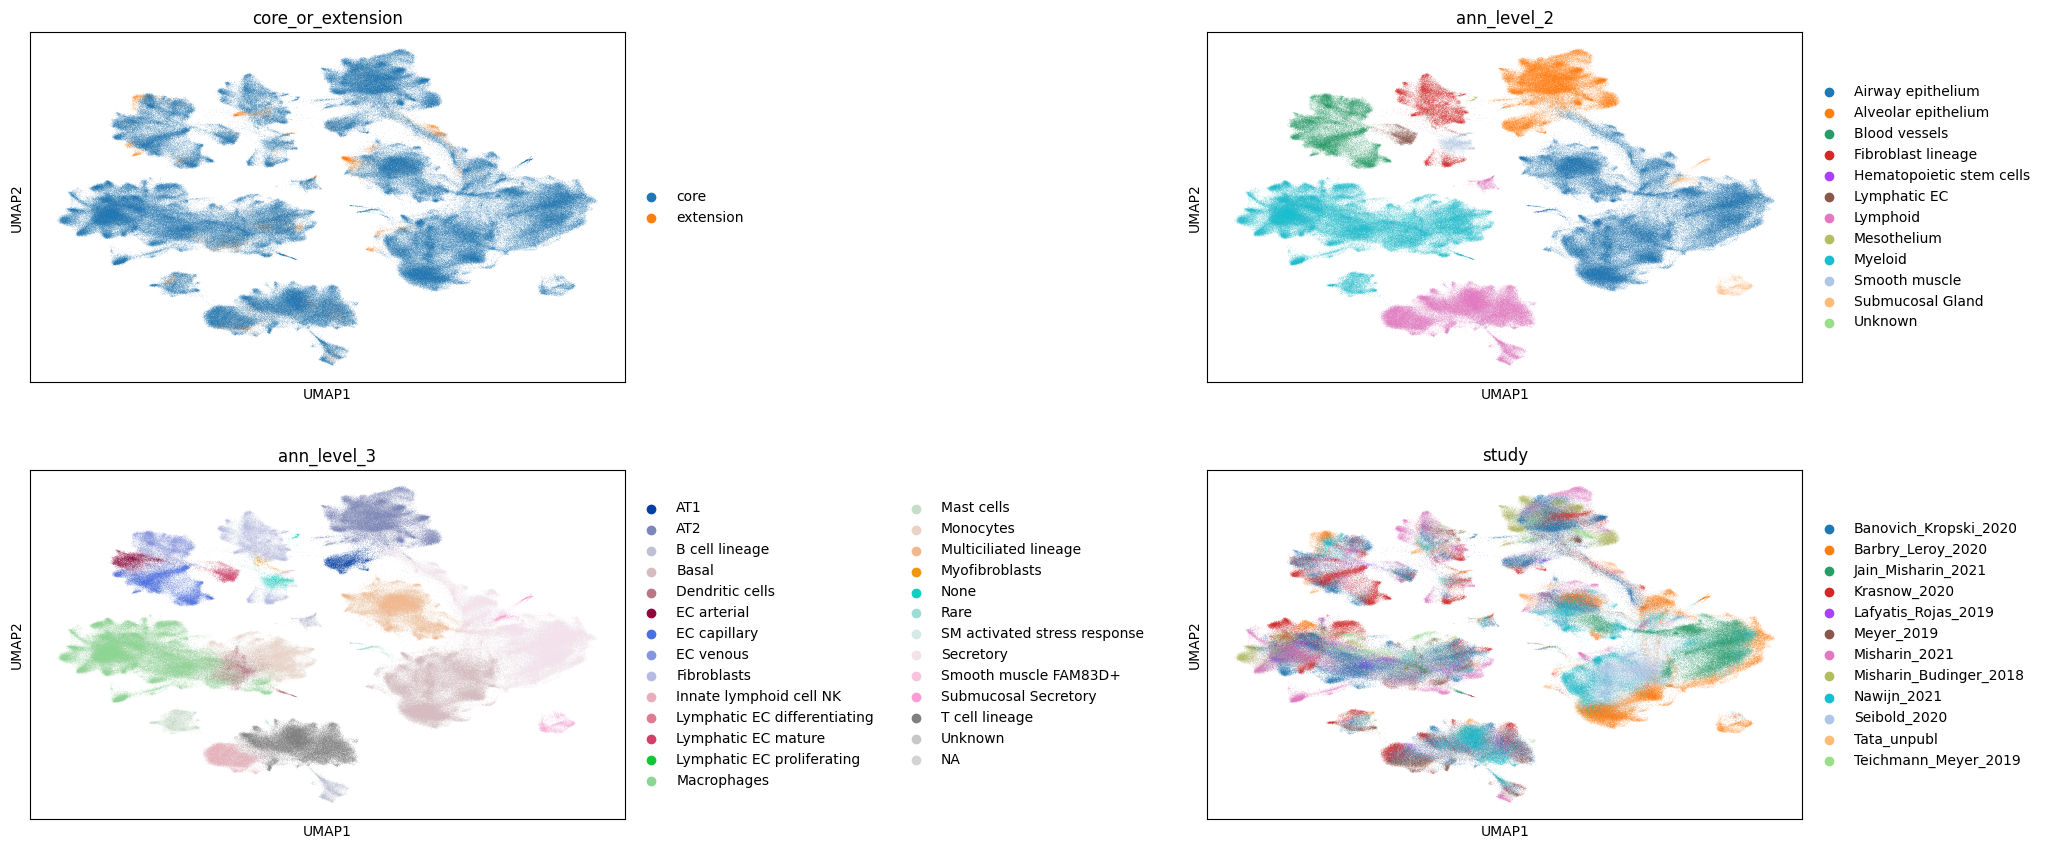

In [28]:
sc.pl.umap(
    latent,
    color=[
        "core_or_extension",
        "ann_level_2",
        "ann_level_3",
        "study",
    ],
    ncols=2,
    wspace=0.8,
)

In [29]:
latent.write(f"./scanvi_models/{query_dataset}/emb.h5ad")